# Proyecto: Predicción de Valores de Vivienda (Housing)
Este cuaderno sigue un flujo completo y estructurado de Ciencia de Datos (Data Science). Abarca desde la carga exploratoria de los datos y su visualización, pasando por la limpieza y preprocesamiento paso a paso, hasta la justificación, entrenamiento y evaluación de un modelo de Machine Learning.

## 1. Importación de Librerías
Importamos todas las herramientas necesarias para manipulación de datos, gráficos y modelado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time

# Modelado y evaluación
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Configuración para que los gráficos se muestren dentro del cuaderno
%matplotlib inline
sns.set_theme(style="whitegrid")

## 2. Carga y Exploración Inicial de Datos (Raw Data)
En este paso cargamos el archivo CSV para ver cómo viene la información originalmente ('en crudo').

In [3]:
df = pd.read_csv('/content/housing.csv')

# Tomamos una muestra aleatoria para agilizar el procesamiento del algoritmo SVM más adelante
df = df.sample(n=3000, random_state=42).reset_index(drop=True)

print("=== Información General del Dataset ===")
df.info()

print("\n=== Primeras 5 filas del Dataset (Raw) ===")
display(df.head())

=== Información General del Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           3000 non-null   float64
 1   latitude            3000 non-null   float64
 2   housing_median_age  3000 non-null   float64
 3   total_rooms         3000 non-null   float64
 4   total_bedrooms      2793 non-null   float64
 5   population          3000 non-null   float64
 6   households          3000 non-null   float64
 7   median_income       3000 non-null   float64
 8   median_house_value  3000 non-null   float64
 9   ocean_proximity     3000 non-null   object 
dtypes: float64(9), object(1)
memory usage: 234.5+ KB

=== Primeras 5 filas del Dataset (Raw) ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-119.01,36.06,25.0,1505.0,NaN,1392.0,359.0,1.6812,47700.0,INLAND
1,-119.46,35.14,30.0,2943.0,NaN,1565.0,584.0,2.5313,45800.0,INLAND
2,-122.44,37.80,52.0,3830.0,NaN,1310.0,963.0,3.4801,500001.0,NEAR BAY
3,-118.72,34.28,17.0,3051.0,NaN,1705.0,495.0,5.7376,218600.0,<1H OCEAN
4,-121.93,36.62,34.0,2351.0,NaN,1063.0,428.0,3.7250,278000.0,NEAR OCEAN


## 3. Análisis Exploratorio de Datos (EDA) y Gráficos
Antes de limpiar, visualizamos los datos para entender su comportamiento, distribución y posibles valores atípicos.

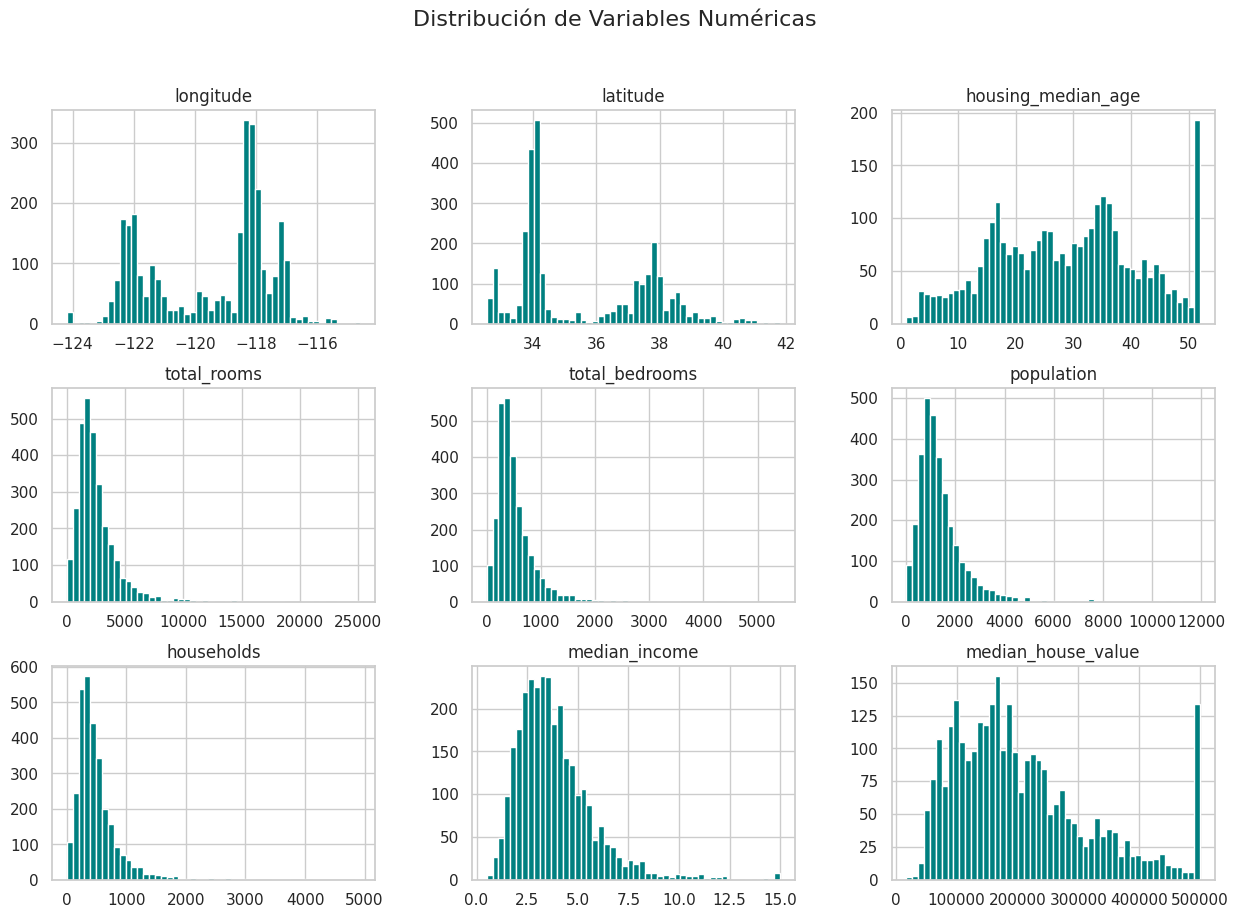

In [4]:
# 3.1 Histogramas de las variables numéricas
df.hist(bins=50, figsize=(15, 10), color='teal')
plt.suptitle('Distribución de Variables Numéricas', fontsize=16)
plt.show()

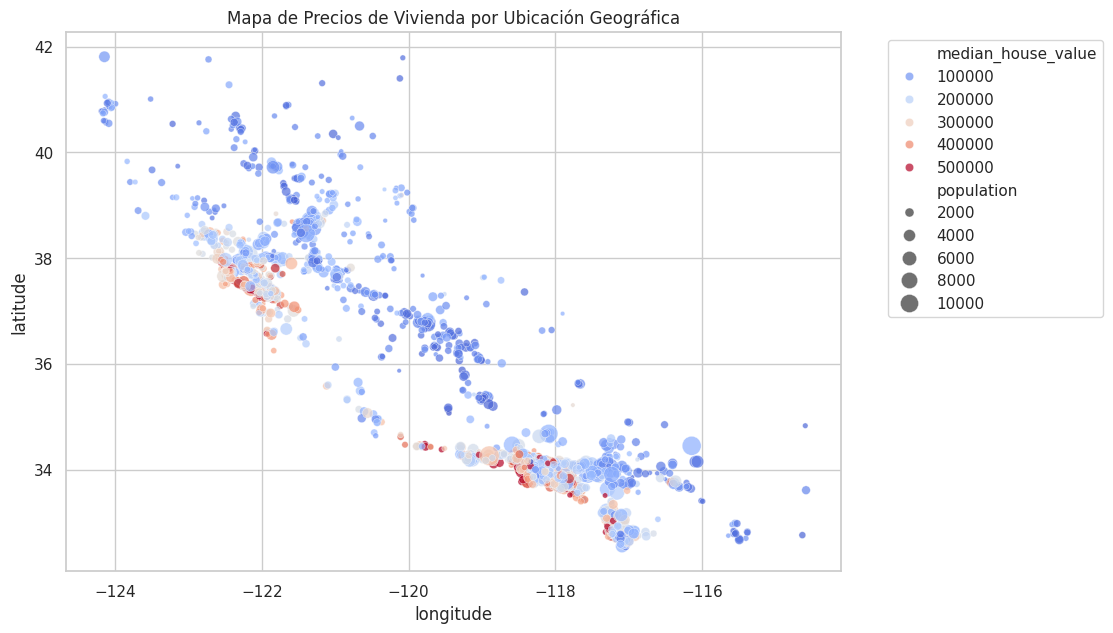

In [5]:
# 3.2 Gráfico de dispersión geográfica (Latitud vs Longitud) coloreado por el valor de la casa
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='longitude', y='latitude', hue='median_house_value',
                palette='coolwarm', size='population', sizes=(10, 200), alpha=0.7)
plt.title('Mapa de Precios de Vivienda por Ubicación Geográfica')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

## 4. Limpieza de Datos (Data Cleaning) paso a paso
El análisis anterior y `df.info()` nos muestran que tenemos valores nulos y una variable categórica (`ocean_proximity`) que la máquina no puede procesar como texto.

In [6]:
print("Valores nulos antes de la limpieza:\n", df.isnull().sum())

# PASO 1: Imputación de nulos.
# Usamos la MEDIANA en 'total_bedrooms' para no afectar la distribución con valores extremos.
mediana_habitaciones = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(mediana_habitaciones)

# PASO 2: Convertir variables categóricas a numéricas (One-Hot Encoding)
# Esto crea columnas binarias para cada categoría de 'ocean_proximity'
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

print("\nValores nulos DESPUÉS de la limpieza:\n", df.isnull().sum())

print("\n=== Así queda el Dataset LIMPIO y Listo para el modelo ===")
display(df.head())

Valores nulos antes de la limpieza:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Valores nulos DESPUÉS de la limpieza:
 longitude                     0
latitude                      0
housing_median_age            0
total_rooms                   0
total_bedrooms                0
population                    0
households                    0
median_income                 0
median_house_value            0
ocean_proximity_INLAND        0
ocean_proximity_NEAR BAY      0
ocean_proximity_NEAR OCEAN    0
dtype: int64

=== Así queda el Dataset LIMPIO y Listo para el modelo ===


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-119.01,36.06,25.0,1505.0,427.0,1392.0,359.0,1.6812,47700.0,True,False,False
1,-119.46,35.14,30.0,2943.0,427.0,1565.0,584.0,2.5313,45800.0,True,False,False
2,-122.44,37.80,52.0,3830.0,427.0,1310.0,963.0,3.4801,500001.0,False,True,False
3,-118.72,34.28,17.0,3051.0,427.0,1705.0,495.0,5.7376,218600.0,False,False,False
4,-121.93,36.62,34.0,2351.0,427.0,1063.0,428.0,3.7250,278000.0,False,False,True


## 5. Matriz de Correlación
Ahora que el dataset es 100% numérico, evaluamos qué variables tienen mayor impacto (correlación) con nuestro Target: `median_house_value`.

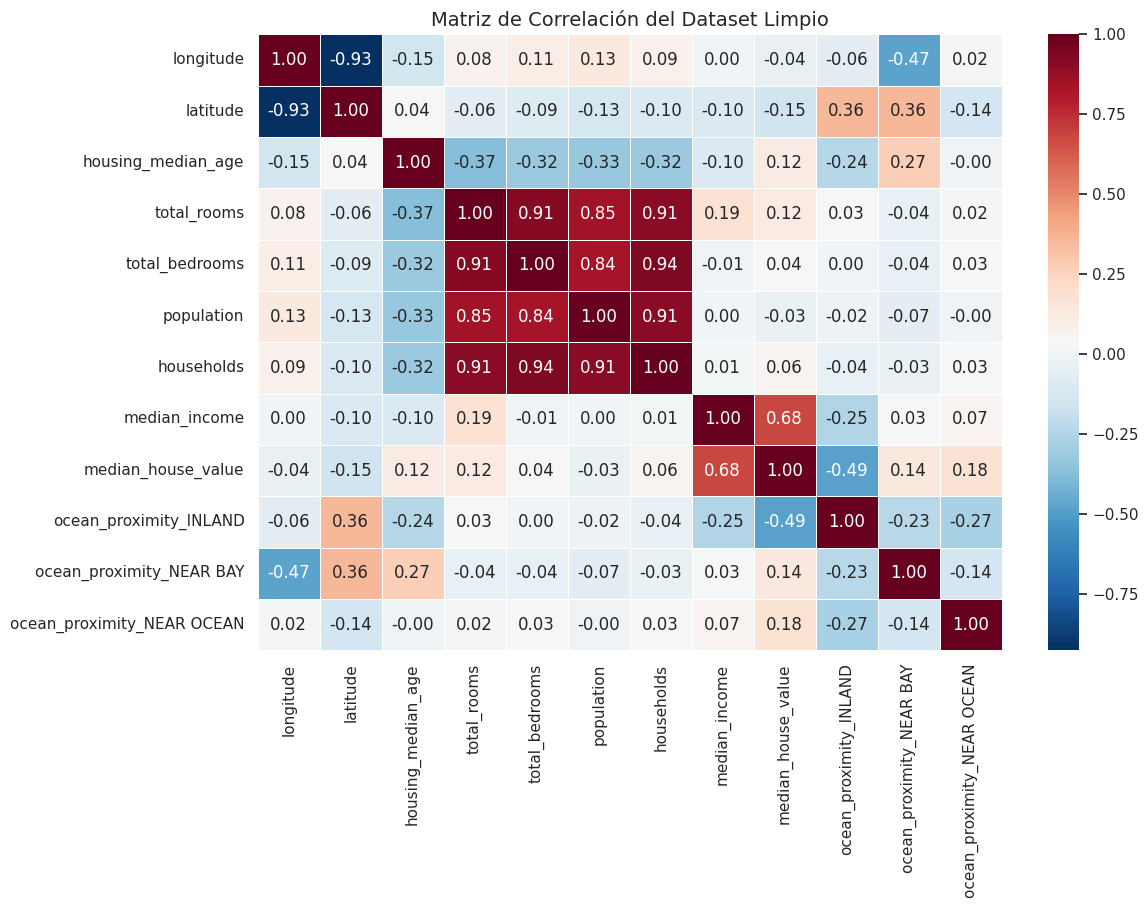

In [7]:
plt.figure(figsize=(12, 8))
correlacion = df.corr()
sns.heatmap(correlacion, annot=True, cmap='RdBu_r', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación del Dataset Limpio', fontsize=14)
plt.show()

# Observación: 'median_income' suele ser la variable con mayor correlación positiva con el precio de la casa.

## 6. Justificación Técnica del Tipo de Problema
**¿Por qué este es un problema de Regresión y no de Clasificación?**
La variable que deseamos predecir es `median_house_value`. Esta variable representa el costo de las viviendas y es continua (ej: $150,000, $210,000, etc.).
La **clasificación** se utiliza cuando predecimos etiquetas categóricas (ej. si una casa es 'Costosa' o 'Económica'). La **regresión** se utiliza cuando buscamos predecir una cantidad numérica exacta en un espectro infinito. Por lo tanto, abordaremos esto con métricas y algoritmos de regresión.

## 7. Selección del Algoritmo, División y Escalado
**Algoritmo seleccionado: Support Vector Regressor (SVR)**
Elegimos SVM (en su versión de regresión, SVR) porque gracias al "truco del kernel" es capaz de proyectar los datos a dimensiones más altas, capturando relaciones no lineales muy complejas (como la relación geográfica de latitud/longitud con el precio). Es más robusto ante valores extremos que una regresión lineal clásica.

*Nota crucial:* SVM es extremadamente sensible a las escalas. Si una variable está en decenas (como la edad de la casa) y otra en decenas de miles (como el salario), el algoritmo fallará. Debemos escalar los datos.

In [8]:
# Separación en X (variables independientes) e Y (variable dependiente / Target)
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

# División 80% Entrenamiento / 20% Prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalado Estandarizado (Media 0, Desviación Estándar 1)
scaler_X = StandardScaler()
scaler_y = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# SVM requiere que 'y' sea un array 1D escalado también
y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1)).flatten()
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1)).flatten()

## 8. Entrenamiento y Prueba de Diferentes Kernels
Entrenaremos el modelo utilizando tres transformaciones (kernels) distintas: Lineal, Polinomial y Radial (RBF) para comparar cuál se adapta mejor a los datos.

In [9]:
kernels = ['linear', 'poly', 'rbf']
resultados_modelos = {}

for k in kernels:
    print(f"Entrenando Modelo SVR con Kernel '{k}'...")
    inicio = time.time()

    # Configuración y entrenamiento
    svr = SVR(kernel=k, C=1.0)
    svr.fit(X_train_scaled, y_train_scaled)

    # Predicción
    preds_scaled = svr.predict(X_test_scaled)

    # Revertir el escalado de las predicciones a dólares reales
    preds = scaler_y.inverse_transform(preds_scaled.reshape(-1, 1)).flatten()

    resultados_modelos[k] = {'predicciones': preds, 'tiempo': time.time() - inicio}

print("\n¡Entrenamiento finalizado!")

Entrenando Modelo SVR con Kernel 'linear'...
Entrenando Modelo SVR con Kernel 'poly'...
Entrenando Modelo SVR con Kernel 'rbf'...

¡Entrenamiento finalizado!


## 9. Evaluación del Modelo (Métricas de Regresión)
Calculamos:
1. **RMSE (Error Cuadrático Medio):** Mide la magnitud promedio del error en dólares, penalizando fuertemente errores grandes.
2. **MAE (Error Absoluto Medio):** Promedio absoluto del error en la predicción. Es más fácil de interpretar.
3. **R² (R-cuadrado):** Proporción de la varianza en la variable objetivo que es explicable por el modelo (más cerca a 1.0 es mejor).

In [10]:
for k, datos in resultados_modelos.items():
    preds = datos['predicciones']

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    print(f"--- RESULTADOS KERNEL {k.upper()} ---")
    print(f"RMSE: ${rmse:,.2f}")
    print(f"MAE:  ${mae:,.2f}")
    print(f"R²:   {r2:.4f}")
    print(f"Tiempo: {datos['tiempo']:.2f} seg\n")

print("Conclusión: El Kernel RBF captura mucho mejor la no-linealidad de los datos geográficos y demográficos.")

--- RESULTADOS KERNEL LINEAR ---
RMSE: $68,170.26
MAE:  $48,858.24
R²:   0.6437
Tiempo: 0.45 seg

--- RESULTADOS KERNEL POLY ---
RMSE: $67,707.36
MAE:  $46,620.46
R²:   0.6485
Tiempo: 0.45 seg

--- RESULTADOS KERNEL RBF ---
RMSE: $57,913.23
MAE:  $40,373.01
R²:   0.7428
Tiempo: 0.21 seg

Conclusión: El Kernel RBF captura mucho mejor la no-linealidad de los datos geográficos y demográficos.


## 10. Visualización de Resultados: Valores Reales vs. Predicciones
Graficaremos qué tan cerca estuvieron las predicciones del mejor modelo (Kernel RBF) de los valores reales.

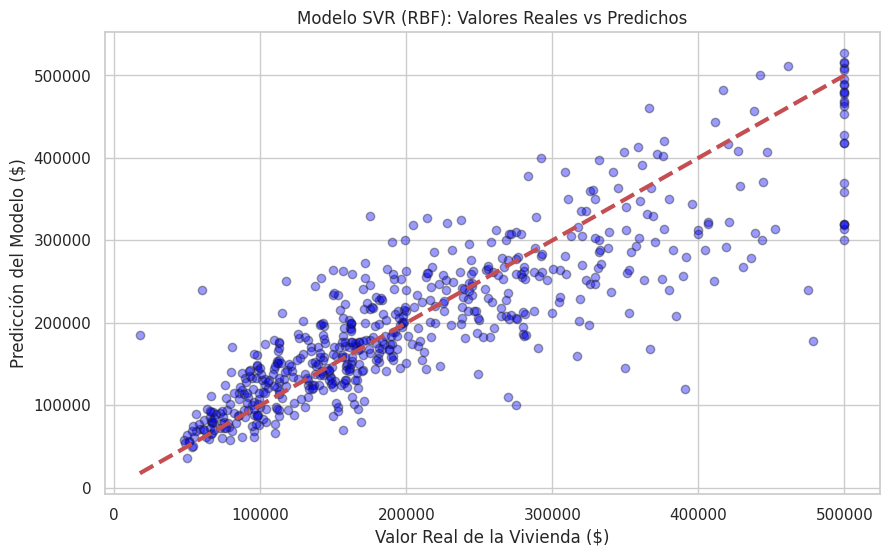

In [11]:
mejores_preds = resultados_modelos['rbf']['predicciones']

plt.figure(figsize=(10, 6))
plt.scatter(y_test, mejores_preds, alpha=0.4, color='blue', edgecolor='k')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=3)
plt.xlabel('Valor Real de la Vivienda ($)')
plt.ylabel('Predicción del Modelo ($)')
plt.title('Modelo SVR (RBF): Valores Reales vs Predichos')
plt.show()